In [1]:
# N-BEATS v7 Evaluation
# Input:  nbeats_experiments_v7/exp01_enc72_pred6/best-v1.ckpt
#         traffic_features_v3.parquet
# Output: nbeats_experiments_v7/exp01_enc72_pred6/test_results.json
#         nbeats_figures_v7/ (all figures)
# Thesis: Chapter 7 (Experimental Results — N-BEATS)

import os
import json
import time
import warnings
warnings.filterwarnings("ignore")

import duckdb
import pandas as pd
import numpy as np
import torch
import lightning.pytorch as pl
import matplotlib.pyplot as plt

from pytorch_forecasting import NBeats, TimeSeriesDataSet
from pytorch_forecasting.metrics import MAE

pl.seed_everything(42, workers=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    torch.set_float32_matmul_precision("medium")

print(f"Device: {device}")
if device == "cuda":
    print(f"GPU:    {torch.cuda.get_device_name(0)}")
    print(f"VRAM:   "
          f"{torch.cuda.get_device_properties(0).total_memory/1e9:.2f} GB")
print(f"PyTorch:           {torch.__version__}")
print(f"PyTorch Lightning: {pl.__version__}")
print()
print("N-BEATS v7 — Final Model Evaluation")
print("="*50)
print("encoder=72h  prediction=6h  weight_decay=λ=1e-4")
print("Best val MAE: 0.1597 z-score  (~83 veh/h)")
print("Val MASE: 0.7109  R≈1.0 from epoch 50")

Seed set to 42


Device: cuda
GPU:    NVIDIA RTX A2000 12GB
VRAM:   12.47 GB
PyTorch:           2.13.0+cu126
PyTorch Lightning: 2.6.5

N-BEATS v7 — Final Model Evaluation
encoder=72h  prediction=6h  weight_decay=λ=1e-4
Best val MAE: 0.1597 z-score  (~83 veh/h)
Val MASE: 0.7109  R≈1.0 from epoch 50


In [2]:
# ── Paths ─────────────────────────────────────────────────────────────────────
FEATURES_PATH = "/home/iai-labor/traffic_project/traffic_features_v3.parquet"
EXP_DIR       = ("/home/iai-labor/traffic_project/"
                 "nbeats_experiments_v7/exp01_enc72_pred6")
FIG_DIR       = "/home/iai-labor/traffic_project/nbeats_figures_v7"
CHECKPOINT    = os.path.join(EXP_DIR, "best-v1.ckpt")
os.makedirs(FIG_DIR, exist_ok=True)

SUBCLASS_NAMES = {0: "URB_normal", 1: "URB_ramp", 2: "M30", 3: "C30"}

# ── Configuration — identical to training ─────────────────────────────────────
FIXED = {
    "sensors_per_class":             50,
    "train_end":              "2025-06-01",
    "val_end":                "2025-12-01",
    "max_encoder_length":            72,   # key change from v6 (was 48)
    "max_prediction_length":          6,
    "stack_types":         ["trend", "seasonality"],
    "num_block_layers":              [4, 4],
    "sharing":                       [True, True],
    "expansion_coefficient_lengths": [3, 7],
    "dropout":                       0.1,
    "batch_size":                    128,  # was 256 in v6
    "patience":                      15,
    "min_delta":                     1e-5,
    "reduce_on_plateau_patience":    4,
    "weight_decay":                  1e-4,
}

# ── Verify checkpoint ─────────────────────────────────────────────────────────
assert os.path.exists(CHECKPOINT), f"Checkpoint not found: {CHECKPOINT}"
ckpt_size = os.path.getsize(CHECKPOINT) / 1e6
print(f"Checkpoint: {CHECKPOINT}")
print(f"Size:       {ckpt_size:.1f} MB")
print()
print(f"N-BEATS v7 configuration:")
print(f"  encoder:       {FIXED['max_encoder_length']}h  (was 48h in v6)")
print(f"  prediction:    {FIXED['max_prediction_length']}h")
print(f"  batch_size:    {FIXED['batch_size']}    (was 256 in v6)")
print(f"  weight_decay:  λ={FIXED['weight_decay']}")
print(f"  scheduler:     ReduceLROnPlateau "
      f"patience={FIXED['reduce_on_plateau_patience']}")
print(f"  Best val MAE:  0.1597 z-score (epoch 91)")
print(f"  Val MASE:      0.7109")
print(f"  R ratio:       0.950–0.955 (R≈1.0 from epoch 50)")
print(f"  Figures:       {FIG_DIR}")

Checkpoint: /home/iai-labor/traffic_project/nbeats_experiments_v7/exp01_enc72_pred6/best-v1.ckpt
Size:       622.6 MB

N-BEATS v7 configuration:
  encoder:       72h  (was 48h in v6)
  prediction:    6h
  batch_size:    128    (was 256 in v6)
  weight_decay:  λ=0.0001
  scheduler:     ReduceLROnPlateau patience=4
  Best val MAE:  0.1597 z-score (epoch 91)
  Val MASE:      0.7109
  R ratio:       0.950–0.955 (R≈1.0 from epoch 50)
  Figures:       /home/iai-labor/traffic_project/nbeats_figures_v7


In [3]:
# ── Sensor selection ──────────────────────────────────────────────────────────
print("Selecting sensors...")
con = duckdb.connect()
sampled = con.sql(f"""
    WITH ranked AS (
        SELECT SENSOR_ID, road_subclass_enc, COUNT(*) AS n_obs,
               ROW_NUMBER() OVER (
                   PARTITION BY road_subclass_enc
                   ORDER BY COUNT(*) DESC, SENSOR_ID ASC
               ) AS rn
        FROM read_parquet('{FEATURES_PATH}')
        WHERE split='train' AND target IS NOT NULL
          AND lag_168h IS NOT NULL
        GROUP BY SENSOR_ID, road_subclass_enc
        HAVING COUNT(*) > 8760
    )
    SELECT SENSOR_ID, road_subclass_enc, n_obs
    FROM ranked
    WHERE rn <= {FIXED['sensors_per_class']}
    ORDER BY road_subclass_enc, SENSOR_ID
""").df()

SENSOR_IDS = sampled["SENSOR_ID"].tolist()
id_list    = ",".join(map(str, SENSOR_IDS))
print(f"  Sensors: {len(SENSOR_IDS)} "
      f"({FIXED['sensors_per_class']} per sub-class)")

# ── Load data ─────────────────────────────────────────────────────────────────
print("Loading data...")
t0 = time.time()
df = con.sql(f"""
    SELECT SENSOR_ID, DATETIME, target, road_subclass_enc, split
    FROM read_parquet('{FEATURES_PATH}')
    WHERE SENSOR_ID IN ({id_list}) AND target IS NOT NULL
    ORDER BY SENSOR_ID, DATETIME
""").df()
df["DATETIME"]   = pd.to_datetime(df["DATETIME"])
df               = df.sort_values(
    ["SENSOR_ID", "DATETIME"]).reset_index(drop=True)
df["sensor_str"] = df["SENSOR_ID"].astype(str)
print(f"  Rows: {len(df):,}  ({time.time()-t0:.1f}s)")

# ── Time index ────────────────────────────────────────────────────────────────
time_origin    = df["DATETIME"].min()
df["time_idx"] = (
    (df["DATETIME"] - time_origin)
    .dt.total_seconds().div(3600).round().astype(int)
)
train_end_idx = int(
    (pd.Timestamp(FIXED["train_end"]) - time_origin).total_seconds()/3600
)
val_end_idx = int(
    (pd.Timestamp(FIXED["val_end"]) - time_origin).total_seconds()/3600
)
BUFFER     = FIXED["max_encoder_length"]   # 72h
train_mask = df["time_idx"] <= train_end_idx

print(f"  train_end_idx: {train_end_idx}  ({FIXED['train_end']})")
print(f"  val_end_idx:   {val_end_idx}  ({FIXED['val_end']})")
print(f"  Buffer:        {BUFFER}h")

# ── Per-sensor z-score normalisation ─────────────────────────────────────────
# Statistics computed from training data only — no leakage
# Per-sensor p99.9 cap prevents hardware fault inflation of σᵢ
print("\nComputing normalisation statistics...")
sensor_stats_list = []
for sid in SENSOR_IDS:
    st      = df.loc[train_mask & (df["SENSOR_ID"]==sid), "target"]
    p999    = float(st.quantile(0.999))
    clean   = st[st <= p999]
    mu_i    = float(clean.mean())
    sigma_i = float(clean.std())
    if sigma_i < 1e-6 or np.isnan(sigma_i):
        sigma_i = 1.0
    sensor_stats_list.append({
        "SENSOR_ID": sid, "mu": mu_i, "sigma": sigma_i, "p999": p999
    })
SENSOR_STATS = pd.DataFrame(sensor_stats_list).set_index("SENSOR_ID")
df["mu_i"]        = df["SENSOR_ID"].map(SENSOR_STATS["mu"])
df["sigma_i"]     = df["SENSOR_ID"].map(SENSOR_STATS["sigma"])
df["target_norm"] = (df["target"] - df["mu_i"]) / df["sigma_i"]

# Verify
is_clean   = df.loc[train_mask, "target"] <= df.loc[
    train_mask, "SENSOR_ID"].map(SENSOR_STATS["p999"])
clean_norm = df.loc[train_mask, "target_norm"][is_clean.values]
print(f"  Clean pop: mean={clean_norm.mean():.4f} "
      f"std={clean_norm.std():.4f}  (expected 0.000, 1.000)")

# ── Splits ────────────────────────────────────────────────────────────────────
df_train = df[df["time_idx"] <= train_end_idx].copy()
df_test  = df[df["time_idx"] > val_end_idx - BUFFER].copy()
print(f"\nSplit sizes (buffer={BUFFER}h):")
print(f"  Train: {len(df_train):>10,}")
print(f"  Test:  {len(df_test):>10,}  (includes {BUFFER}h buffer)")

# Gap check
gap_check = (
    df.groupby("SENSOR_ID")["time_idx"]
      .apply(lambda x: (x.diff().dropna() != 1).sum())
)
print(f"  Gaps:  {(gap_check>0).sum()} sensors — "
      f"{'clean' if (gap_check>0).sum()==0 else 'GAPS DETECTED'}")

MEAN_SIGMA       = float(SENSOR_STATS["sigma"].mean())
SENSOR_STR_ORDER = df_train["sensor_str"].unique().tolist()
print(f"\nMean σ across sensors: {MEAN_SIGMA:.1f} veh/h")
print(f"SENSOR_STATS ready for {len(SENSOR_STATS)} sensors")

Selecting sensors...
  Sensors: 200 (50 per sub-class)
Loading data...
  Rows: 5,981,200  (2.4s)
  train_end_idx: 21168  (2025-06-01)
  val_end_idx:   25560  (2025-12-01)
  Buffer:        72h

Computing normalisation statistics...
  Clean pop: mean=-0.0000 std=1.0000  (expected 0.000, 1.000)

Split sizes (buffer=72h):
  Train:  4,233,800
  Test:     883,400  (includes 72h buffer)
  Gaps:  0 sensors — clean

Mean σ across sensors: 522.8 veh/h
SENSOR_STATS ready for 200 sensors


In [4]:
# ── Recreate datasets ─────────────────────────────────────────────────────────
# Identical configuration to training — ensures prediction windows
# match exactly what the model was trained on
print("Creating datasets...")
t0 = time.time()

training_dataset = TimeSeriesDataSet(
    df_train,
    time_idx      = "time_idx",
    target        = "target_norm",
    group_ids     = ["sensor_str"],
    max_encoder_length    = FIXED["max_encoder_length"],    # 72
    min_encoder_length    = FIXED["max_encoder_length"],    # 72
    max_prediction_length = FIXED["max_prediction_length"], # 6
    min_prediction_length = FIXED["max_prediction_length"], # 6
    time_varying_unknown_reals = ["target_norm"],
    target_normalizer          = None,
    add_relative_time_idx      = False,
    add_target_scales          = False,
    add_encoder_length         = False,
    allow_missing_timesteps    = False,
)

test_dataset = TimeSeriesDataSet.from_dataset(
    training_dataset,
    df_test,
    min_prediction_idx = val_end_idx + 1,
    predict            = False,
    stop_randomization = True,
)

# Boundary assertion — no test target falls in validation or training period
assert test_dataset.min_prediction_idx >= val_end_idx + 1, (
    f"CONTAMINATION: test predictions start at "
    f"{test_dataset.min_prediction_idx} ≤ val_end_idx={val_end_idx}"
)

test_loader = test_dataset.to_dataloader(
    train      = False,
    batch_size = FIXED["batch_size"] * 2,  # 256 — no gradients, safe
    num_workers = 4,
    pin_memory  = True,
)

print(f"  Created in {time.time()-t0:.1f}s")
print(f"  Test windows:  {len(test_dataset):,}")
print(f"  Test batches:  {len(test_loader):,}  (batch=256)")
print(f"  ✓ Boundary assertion passed — "
      f"test starts at time_idx={test_dataset.min_prediction_idx}")

# Sample verification
sample_x, sample_y = test_dataset[0]
enc_vals = sample_x["encoder_target"].numpy()
print(f"\nSample test window:")
print(f"  encoder shape:    {enc_vals.shape}  (expected (72,))")
print(f"  prediction shape: {sample_y[0].shape}  (expected (6,))")
print(f"  z-score range:    [{enc_vals.min():.3f}, {enc_vals.max():.3f}]")

if enc_vals.shape[0] == FIXED["max_encoder_length"]:
    print(f"  ✓ Encoder=72h confirmed")
else:
    print(f"  ✗ Encoder mismatch — check dataset construction")
if sample_y[0].shape[0] == FIXED["max_prediction_length"]:
    print(f"  ✓ Prediction=6h confirmed")
else:
    print(f"  ✗ Prediction mismatch — check dataset construction")

Creating datasets...
  Created in 5.3s
  Test windows:  868,000
  Test batches:  3,391  (batch=256)
  ✓ Boundary assertion passed — test starts at time_idx=25561

Sample test window:
  encoder shape:    (72,)  (expected (72,))
  prediction shape: torch.Size([6])  (expected (6,))
  z-score range:    [-1.474, 0.075]
  ✓ Encoder=72h confirmed
  ✓ Prediction=6h confirmed


In [5]:
# ── Metric functions ──────────────────────────────────────────────────────────
def compute_all_metrics(preds, actuals, naive_mae):
    preds   = preds.flatten().astype(float)
    actuals = actuals.flatten().astype(float)
    errors  = preds - actuals
    abs_e   = np.abs(errors)
    mae     = float(np.mean(abs_e))
    rmse    = float(np.sqrt(np.mean(errors**2)))
    mase    = float(mae/naive_mae) if naive_mae > 1e-8 else float("nan")
    denom   = np.abs(preds) + np.abs(actuals)
    smape   = float(np.mean(
        np.where(denom > 1e-8, 2.0*abs_e/denom, 0.0))*100)
    ss_res  = float(np.sum(errors**2))
    ss_tot  = float(np.sum((actuals - actuals.mean())**2))
    r2      = float(1.0-ss_res/ss_tot) if ss_tot > 1e-8 else float("nan")
    return {
        "MAE":   round(mae,   2),
        "RMSE":  round(rmse,  2),
        "MASE":  round(mase,  4),
        "SMAPE": round(smape, 2),
        "R2":    round(r2,    4),
    }

def inverse_transform(pred_norm, actual_norm, sensor_str_array):
    try:
        mu_arr    = np.array([
            SENSOR_STATS.loc[int(s), "mu"] for s in sensor_str_array
        ], dtype=float)
        sigma_arr = np.array([
            SENSOR_STATS.loc[int(s), "sigma"] for s in sensor_str_array
        ], dtype=float)
    except KeyError as e:
        raise KeyError(f"Sensor {e} not in SENSOR_STATS")
    pred_veh   = pred_norm   * sigma_arr[:, None] + mu_arr[:, None]
    actual_veh = actual_norm * sigma_arr[:, None] + mu_arr[:, None]
    return np.clip(pred_veh, 0, None).astype(float), actual_veh.astype(float)

print("Metric functions defined.")

# ── Sensor lookup for exact naive MAE ─────────────────────────────────────────
# Full sensor series indexed by time_idx — used in MASE denominator
# Reference: Hyndman & Koehler (2006) IJF 22(4):679-688
# MASE invariant: numerator and denominator over same population
SENSOR_FULL = {
    str(sid): (
        df[df["SENSOR_ID"] == sid]
        .sort_values("time_idx")
        .set_index("time_idx")["target"]
    )
    for sid in SENSOR_IDS
}
print(f"SENSOR_FULL built for {len(SENSOR_FULL)} sensors.")

def compute_exact_naive_mae(timestamps, actuals_veh, sensors):
    """
    Seasonal naive MAE over EXACTLY the model prediction population.
    Naive: ŷₜ = yₜ₋₁₆₈ (same hour one week ago).
    Hard assert if any lag missing — ensures exact population match.
    """
    errors  = []
    missing = []
    for i in range(len(timestamps)):
        t_idx = int(timestamps[i])
        lag_t = t_idx - 168
        s     = SENSOR_FULL.get(sensors[i])
        if s is None or lag_t not in s.index:
            missing.append((sensors[i], t_idx, lag_t))
            continue
        errors.append(abs(float(actuals_veh[i]) - float(s.loc[lag_t])))
    assert len(missing) == 0, (
        f"Missing seasonal-naive lag values for "
        f"{len(missing)} predictions. First 3: {missing[:3]}"
    )
    assert len(errors) == len(timestamps)
    return float(np.mean(errors))

# ── Test naive baseline ───────────────────────────────────────────────────────
# Seasonal naive: ŷₜ = yₜ₋₁₆₈ over exact test prediction targets
# Weekly period (168h) unchanged — dominant seasonality confirmed by EDA
print("\nComputing test naive baseline MAE...")
naive_errors = []
for sid in SENSOR_IDS:
    fs = SENSOR_FULL[str(sid)]
    for t, actual in fs[fs.index > val_end_idx].items():
        lag_t = t - 168
        if lag_t in fs.index:
            naive_errors.append(abs(actual - float(fs.loc[lag_t])))
assert len(naive_errors) > 0
naive_mae = float(np.mean(naive_errors))
print(f"  Test naive MAE:  {naive_mae:.2f} veh/h")
print(f"  Observations:    {len(naive_errors):,}")

# ── Validation naive baseline ─────────────────────────────────────────────────
print("\nComputing validation naive baseline MAE...")
val_naive_errors = []
for sid in SENSOR_IDS:
    fs = SENSOR_FULL[str(sid)]
    for t, actual in fs[
        (fs.index > train_end_idx) & (fs.index <= val_end_idx)
    ].items():
        lag_t = t - 168
        if lag_t in fs.index:
            val_naive_errors.append(abs(actual - float(fs.loc[lag_t])))
assert len(val_naive_errors) > 0
val_naive_mae = float(np.mean(val_naive_errors))
print(f"  Val naive MAE:   {val_naive_mae:.2f} veh/h")
print(f"  Observations:    {len(val_naive_errors):,}")

# ── Summary ───────────────────────────────────────────────────────────────────
print(f"\n{'='*50}")
print(f"Naive baselines confirmed:")
print(f"  val_naive_mae = {val_naive_mae:.2f} veh/h  [val MASE denom]")
print(f"  naive_mae     = {naive_mae:.2f} veh/h  [test MASE denom]")
print(f"  Difficulty gap: {naive_mae/val_naive_mae:.3f}x "
      f"(test period harder by "
      f"{(naive_mae/val_naive_mae - 1)*100:.1f}%)")
print(f"{'='*50}")

Metric functions defined.
SENSOR_FULL built for 200 sensors.

Computing test naive baseline MAE...
  Test naive MAE:  139.20 veh/h
  Observations:    869,000

Computing validation naive baseline MAE...
  Val naive MAE:   105.63 veh/h
  Observations:    878,400

Naive baselines confirmed:
  val_naive_mae = 105.63 veh/h  [val MASE denom]
  naive_mae     = 139.20 veh/h  [test MASE denom]
  Difficulty gap: 1.318x (test period harder by 31.8%)


In [6]:
# ── Load best checkpoint ──────────────────────────────────────────────────────
print(f"Loading checkpoint...")
print(f"  {CHECKPOINT}")
t0 = time.time()
best_model = NBeats.load_from_checkpoint(CHECKPOINT)
best_model.eval().to(device)
n_params = sum(p.numel() for p in best_model.parameters()
               if p.requires_grad)
print(f"  Parameters:  {n_params:,}")
print(f"  Device:      {device}")
print(f"  Load time:   {time.time()-t0:.1f}s")

# ── Collect test predictions ──────────────────────────────────────────────────
print(f"\nCollecting test predictions...")
print(f"  Batches: {len(test_loader):,}  (batch=256)")
t0 = time.time()

preds_list      = []
actuals_list    = []
sensors_list    = []
timestamps_list = []

with torch.no_grad():
    for batch_idx, (x_b, y_b) in enumerate(test_loader):
        x_gpu = {
            k: v.to(device) if isinstance(v, torch.Tensor) else v
            for k, v in x_b.items()
        }
        out = best_model(x_gpu)

        # N-BEATS output shape: (batch, 6, 1) → squeeze to (batch, 6)
        preds_list.append(out.prediction.squeeze(-1).cpu())
        actuals_list.append(y_b[0].cpu())

        sensors_list.append(np.array([
            SENSOR_STR_ORDER[int(g)]
            for g in x_b["groups"].numpy().flatten()
        ]))
        timestamps_list.append(x_b["decoder_time_idx"].numpy())

        if (batch_idx + 1) % 500 == 0:
            elapsed = time.time() - t0
            pct     = (batch_idx + 1) / len(test_loader) * 100
            eta     = elapsed / (batch_idx + 1) * \
                      (len(test_loader) - batch_idx - 1)
            print(f"  [{batch_idx+1:>4}/{len(test_loader)}] "
                  f"{pct:.1f}%  elapsed={elapsed/60:.1f}m  "
                  f"eta={eta/60:.1f}m")

collect_min = (time.time() - t0) / 60
print(f"  Done in {collect_min:.1f} min")

# ── Concatenate ───────────────────────────────────────────────────────────────
pred_norm   = torch.cat(preds_list,   dim=0).numpy()
actual_norm = torch.cat(actuals_list, dim=0).numpy()
sensor_arr  = np.concatenate(sensors_list,    axis=0)
ts_arr      = np.concatenate(timestamps_list, axis=0)

# Shape assertions
assert pred_norm.shape == actual_norm.shape, "Shape mismatch"
assert pred_norm.shape[0] == len(test_dataset), (
    f"Window count mismatch: {pred_norm.shape[0]} vs {len(test_dataset)}"
)
assert pred_norm.shape[1] == FIXED["max_prediction_length"], (
    f"Horizon mismatch: {pred_norm.shape[1]}"
)
assert ts_arr.shape == pred_norm.shape, "Timestamp shape mismatch"

print(f"\nPredictions shape: {pred_norm.shape}  (z-score, 6 horizons)")
print(f"Sensors shape:     {sensor_arr.shape}")
print(f"Timestamps shape:  {ts_arr.shape}")

# ── Inverse transform ─────────────────────────────────────────────────────────
print("\nInverse transforming to veh/h...")
pred_veh, actual_veh = inverse_transform(
    pred_norm, actual_norm, sensor_arr
)
print(f"  Pred  range: [{pred_veh.min():.1f}, {pred_veh.max():.1f}] veh/h")
print(f"  Actual range: [{actual_veh.min():.1f}, "
      f"{actual_veh.max():.1f}] veh/h")

# ── Save arrays ───────────────────────────────────────────────────────────────
np.save(os.path.join(EXP_DIR, "pred_veh.npy"),   pred_veh)
np.save(os.path.join(EXP_DIR, "actual_veh.npy"), actual_veh)
np.save(os.path.join(EXP_DIR, "sensor_arr.npy"), sensor_arr)
np.save(os.path.join(EXP_DIR, "ts_arr.npy"),     ts_arr)
print(f"\nArrays saved to {EXP_DIR}")

# Free GPU memory
del best_model
torch.cuda.empty_cache()
print(f"GPU memory freed.")
print(f"GPU alloc: {torch.cuda.memory_allocated()/1e9:.2f} GB")

Loading checkpoint...
  /home/iai-labor/traffic_project/nbeats_experiments_v7/exp01_enc72_pred6/best-v1.ckpt
  Parameters:  51,870,720
  Device:      cuda
  Load time:   0.8s

  Batches: 3,391  (batch=256)
  [ 500/3391] 14.7%  elapsed=0.1m  eta=0.5m
  [1000/3391] 29.5%  elapsed=0.2m  eta=0.4m
  [1500/3391] 44.2%  elapsed=0.3m  eta=0.3m
  [2000/3391] 59.0%  elapsed=0.3m  eta=0.2m
  [2500/3391] 73.7%  elapsed=0.4m  eta=0.1m
  [3000/3391] 88.5%  elapsed=0.5m  eta=0.1m
  Done in 0.6 min

Predictions shape: (868000, 6)  (z-score, 6 horizons)
Sensors shape:     (868000,)
Timestamps shape:  (868000, 6)

Inverse transforming to veh/h...
  Pred  range: [0.0, 8266.1] veh/h
  Actual range: [-0.0, 7666.2] veh/h

Arrays saved to /home/iai-labor/traffic_project/nbeats_experiments_v7/exp01_enc72_pred6
GPU memory freed.
GPU alloc: 0.01 GB


In [7]:
# ── Per-horizon test metrics ──────────────────────────────────────────────────
print(f"\n{'='*65}")
print(f"N-BEATS v7 TEST RESULTS")
print(f"  encoder=72h | prediction=6h | weight_decay=λ=1e-4")
print(f"  Normalisation: per-sensor z-score, target_normalizer=None")
print(f"  Loss: MAE on z-score | frozen eval — identical to val")
print(f"  Best checkpoint: epoch 91, val MAE=0.1597")
print(f"{'='*65}")
print(f"{'Horizon':<10} {'MAE':>8} {'RMSE':>8} "
      f"{'MASE':>7} {'SMAPE':>7} {'R²':>7} {'NaiveMAE':>10}")
print(f"{'-'*62}")

horizon_metrics_test = {}
horizon_naive_test   = {}

for h in range(FIXED["max_prediction_length"]):
    h_label = f"t+{h+1}h"
    h_ts    = ts_arr[:, h]
    h_act   = actual_veh[:, h]

    # Exact-population naive MAE for this horizon
    h_naive = compute_exact_naive_mae(h_ts, h_act, sensor_arr)
    horizon_naive_test[h_label] = h_naive

    m = compute_all_metrics(pred_veh[:, h], h_act, h_naive)
    horizon_metrics_test[h_label] = m

    status = "✓" if m["MASE"] < 1.0 else "✗"
    print(f"{h_label:<10} {m['MAE']:>8.2f} {m['RMSE']:>8.2f} "
          f"{m['MASE']:>7.4f} {m['SMAPE']:>7.2f} "
          f"{m['R2']:>7.4f} {h_naive:>10.2f} {status}")

# Overall — arithmetic mean of per-horizon values
overall_test = {
    metric: round(float(np.mean([
        horizon_metrics_test[f"t+{h+1}h"][metric]
        for h in range(FIXED["max_prediction_length"])
    ])), 4 if metric in ["MASE", "R2"] else 2)
    for metric in ["MAE", "RMSE", "MASE", "SMAPE", "R2"]
}
print(f"{'-'*62}")
print(f"{'Overall':<10} {overall_test['MAE']:>8.2f} "
      f"{overall_test['RMSE']:>8.2f} "
      f"{overall_test['MASE']:>7.4f} "
      f"{overall_test['SMAPE']:>7.2f} "
      f"{overall_test['R2']:>7.4f}")
print(f"(Overall = arithmetic mean of 6 per-horizon values)")
print(f"{'='*65}")

# ── Sub-class analysis ────────────────────────────────────────────────────────
sensor_to_class = (
    df.drop_duplicates("sensor_str")
      .set_index("sensor_str")["road_subclass_enc"]
      .astype(int).to_dict()
)
window_subclass = np.array([
    sensor_to_class.get(s, -1) for s in sensor_arr
])

print(f"\n{'='*65}")
print(f"N-BEATS v7 — Per Road Sub-Class (test)")
print(f"{'='*65}")
print(f"{'Sub-class':<14} {'MAE':>8} {'RMSE':>8} "
      f"{'MASE':>7} {'SMAPE':>7} {'R²':>7} {'Windows':>10}")
print(f"{'-'*65}")

subclass_results = {}
for enc, name in SUBCLASS_NAMES.items():
    mask = window_subclass == enc
    if mask.sum() == 0:
        continue
    m = compute_all_metrics(
        pred_veh[mask].flatten(),
        actual_veh[mask].flatten(),
        naive_mae
    )
    m["n_windows"] = int(mask.sum())
    subclass_results[name] = m
    print(f"{name:<14} {m['MAE']:>8.2f} {m['RMSE']:>8.2f} "
          f"{m['MASE']:>7.4f} {m['SMAPE']:>7.2f} "
          f"{m['R2']:>7.4f} {mask.sum():>10,}")
print(f"{'='*65}")

# ── Peak vs off-peak ──────────────────────────────────────────────────────────
window_dt    = pd.to_datetime([
    time_origin + pd.Timedelta(hours=int(ts_arr[i, 0]))
    for i in range(len(ts_arr))
])
window_hours = window_dt.hour
window_dow   = pd.Series(window_dt).dt.dayofweek.values

morning_mask  = (window_hours >= 6)  & (window_hours <= 9)
evening_mask  = (window_hours >= 17) & (window_hours <= 20)
weekend_mask  = window_dow >= 5
offpeak_mask  = ~(morning_mask | evening_mask) & ~weekend_mask

print(f"\n{'='*65}")
print(f"N-BEATS v7 — Peak vs Off-Peak (test)")
print(f"{'='*65}")
print(f"{'Period':<16} {'MAE':>8} {'RMSE':>8} "
      f"{'MASE':>7} {'SMAPE':>7} {'R²':>7} {'Windows':>10}")
print(f"{'-'*68}")

period_results = {}
for label, mask in [
    ("Morning peak",  morning_mask),
    ("Evening peak",  evening_mask),
    ("Weekend",       weekend_mask),
    ("Off-peak wkdy", offpeak_mask),
]:
    if mask.sum() == 0:
        continue
    m = compute_all_metrics(
        pred_veh[mask].flatten(),
        actual_veh[mask].flatten(),
        naive_mae
    )
    m["n_windows"] = int(mask.sum())
    period_results[label] = m
    print(f"{label:<16} {m['MAE']:>8.2f} {m['RMSE']:>8.2f} "
          f"{m['MASE']:>7.4f} {m['SMAPE']:>7.2f} "
          f"{m['R2']:>7.4f} {mask.sum():>10,}")
print(f"{'='*65}")

# ── Save results ──────────────────────────────────────────────────────────────
results_test = {
    "model":             "N-BEATS v7",
    "checkpoint":        CHECKPOINT,
    "encoder_length":    FIXED["max_encoder_length"],
    "pred_length":       FIXED["max_prediction_length"],
    "best_val_loss":     0.1597,
    "best_val_epoch":    91,
    "training_epochs":   108,
    "weight_decay":      FIXED["weight_decay"],
    "test_naive_mae":    naive_mae,
    "val_naive_mae":     val_naive_mae,
    "horizon_metrics":   horizon_metrics_test,
    "horizon_naive":     horizon_naive_test,
    "overall":           overall_test,
    "subclass":          subclass_results,
    "period":            period_results,
}
out_json = os.path.join(EXP_DIR, "test_results.json")
with open(out_json, "w") as f:
    json.dump(results_test, f, indent=2)
print(f"\nTest results saved: {out_json}")


N-BEATS v7 TEST RESULTS
  encoder=72h | prediction=6h | weight_decay=λ=1e-4
  Normalisation: per-sensor z-score, target_normalizer=None
  Loss: MAE on z-score | frozen eval — identical to val
  Best checkpoint: epoch 91, val MAE=0.1597
Horizon         MAE     RMSE    MASE   SMAPE      R²   NaiveMAE
--------------------------------------------------------------
t+1h          66.07   151.00  0.4746   26.25  0.9782     139.21 ✓
t+2h          80.47   188.71  0.5780   28.36  0.9660     139.24 ✓
t+3h          87.89   203.27  0.6311   29.70  0.9605     139.26 ✓
t+4h          91.84   212.17  0.6593   30.16  0.9570     139.29 ✓
t+5h          92.35   215.65  0.6629   29.96  0.9556     139.31 ✓
t+6h          93.87   219.68  0.6737   30.30  0.9539     139.33 ✓
--------------------------------------------------------------
Overall       85.42   198.41  0.6133   29.12  0.9619
(Overall = arithmetic mean of 6 per-horizon values)

N-BEATS v7 — Per Road Sub-Class (test)
Sub-class           MAE     RMSE

Epochs with frozen train loss: 107
Epochs with val loss:          107
LR column: lr-Adam


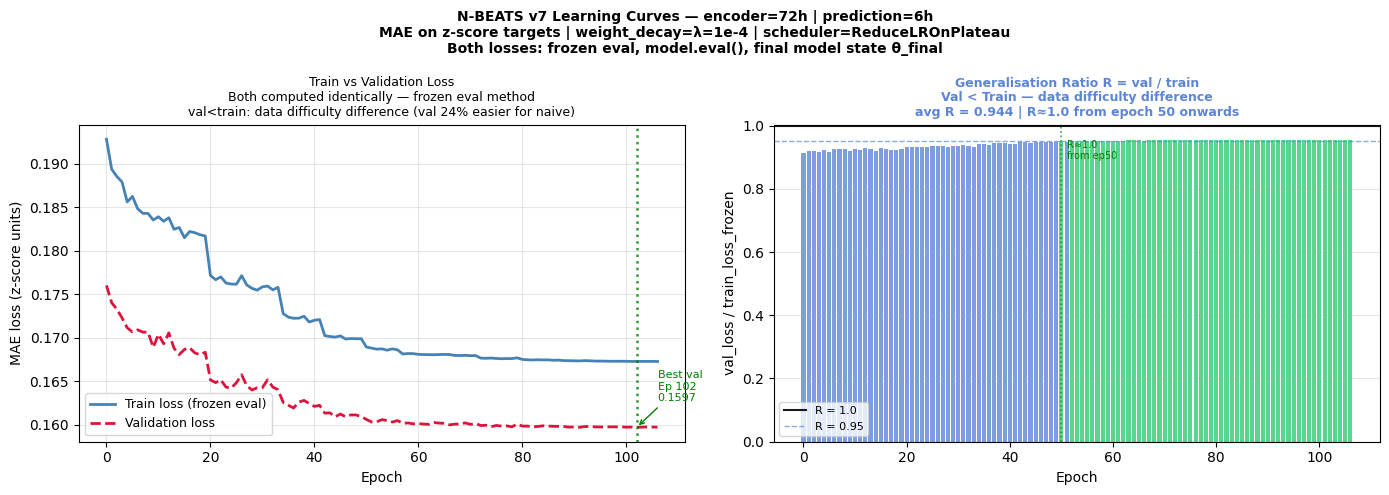

Saved: /home/iai-labor/traffic_project/nbeats_figures_v7/nbeats_v7_loss_curves.png

Loss curve summary:
  Train: 0.1928 → 0.1673
  Val:   0.1760 → 0.1597
  Best val epoch: 102  loss=0.1597
  Avg R ratio:    0.944
  Diagnosis:      Val < Train — data difficulty difference


In [8]:
# ── Load training metrics from CSV ────────────────────────────────────────────
csv_path = os.path.join(EXP_DIR, "logs", "version_0", "metrics.csv")
assert os.path.exists(csv_path), f"Not found: {csv_path}"
metrics_df = pd.read_csv(csv_path)

frozen_rows = metrics_df[
    metrics_df["train_loss_frozen"].notna()
].copy().reset_index(drop=True)
val_rows = metrics_df[
    metrics_df["val_loss"].notna()
].copy().reset_index(drop=True)

print(f"Epochs with frozen train loss: {len(frozen_rows)}")
print(f"Epochs with val loss:          {len(val_rows)}")

lr_col = next(
    (c for c in metrics_df.columns if c.lower().startswith("lr")), None
)
print(f"LR column: {lr_col}")

# ── Figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    "N-BEATS v7 Learning Curves — encoder=72h | prediction=6h\n"
    "MAE on z-score targets | weight_decay=λ=1e-4 | "
    "scheduler=ReduceLROnPlateau\n"
    "Both losses: frozen eval, model.eval(), final model state θ_final",
    fontsize=10, fontweight="bold"
)

# ── Panel 1: Train vs Val loss ────────────────────────────────────────────────
ax1 = axes[0]
ax1.plot(frozen_rows["epoch"].values,
         frozen_rows["train_loss_frozen"].values,
         color="steelblue", linewidth=2.0,
         label="Train loss (frozen eval)")
ax1.plot(val_rows["epoch"].values,
         val_rows["val_loss"].values,
         color="crimson", linewidth=2.0,
         linestyle="--", label="Validation loss")

# Best val marker
best_epoch = int(val_rows.loc[val_rows["val_loss"].idxmin(), "epoch"])
best_loss  = float(val_rows["val_loss"].min())
ax1.axvline(x=best_epoch, color="green",
            linestyle=":", linewidth=1.8, alpha=0.8)
ax1.annotate(
    f"Best val\nEp {best_epoch}\n{best_loss:.4f}",
    xy=(best_epoch, best_loss),
    xytext=(best_epoch + 4, best_loss + 0.003),
    fontsize=8, color="green",
    arrowprops=dict(arrowstyle="->", color="green", lw=1.0)
)

# LR reduction markers
if lr_col:
    lr_rows = metrics_df[
        metrics_df[lr_col].notna() &
        metrics_df["epoch"].notna()
    ].copy()
    y_top   = float(frozen_rows["train_loss_frozen"].max())
    prev_lr = None
    for _, row in lr_rows.iterrows():
        if pd.isna(row["epoch"]):
            continue
        cur_lr = float(row[lr_col])
        if prev_lr is not None and cur_lr < prev_lr - 1e-8:
            ep = int(row["epoch"])
            ax1.axvline(x=ep, color="purple",
                        linestyle=":", linewidth=1.2, alpha=0.5)
            ax1.text(ep + 0.5, y_top,
                     f"LR\n{cur_lr:.0e}",
                     fontsize=6, color="purple",
                     va="top", alpha=0.8)
        prev_lr = cur_lr

ax1.set_xlabel("Epoch", fontsize=10)
ax1.set_ylabel("MAE loss (z-score units)", fontsize=10)
ax1.set_title(
    "Train vs Validation Loss\n"
    "Both computed identically — frozen eval method\n"
    "val<train: data difficulty difference (val 24% easier for naive)",
    fontsize=9
)
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

# ── Panel 2: Generalisation ratio R = val / train ────────────────────────────
ax2 = axes[1]
merged = pd.merge(
    frozen_rows[["epoch", "train_loss_frozen"]],
    val_rows[["epoch", "val_loss"]],
    on="epoch", how="inner"
)
ratio     = merged["val_loss"] / merged["train_loss_frozen"]
avg_ratio = float(ratio.mean())

bar_colors = [
    "#5c85d6" if r < 0.95 else
    "#2ecc71" if r < 1.05 else
    "#27ae60" if r < 1.50 else
    "#f39c12"
    for r in ratio
]
ax2.bar(merged["epoch"].values, ratio.values,
        color=bar_colors, alpha=0.80)
ax2.axhline(y=1.0, color="black", linewidth=1.5,
            alpha=0.9, label="R = 1.0")
ax2.axhline(y=0.95, color="#5c85d6", linewidth=1.0,
            linestyle="--", alpha=0.7, label="R = 0.95")

# Epoch 50 marker — R≈1.0 begins
ax2.axvline(x=50, color="green", linewidth=1.2,
            linestyle=":", alpha=0.7)
ax2.text(51, ratio.max(),
         "R≈1.0\nfrom ep50",
         fontsize=7, color="green", va="top")

# Trajectory diagnosis
val_vals = val_rows["val_loss"].values
if len(val_vals) >= 10:
    slope  = float(np.polyfit(
        np.arange(len(val_vals[-10:])), val_vals[-10:], 1
    )[0])
    rising = slope > 1e-4
else:
    rising = False

if rising:
    diagnosis, col = "Val loss rising — overfitting", "#e74c3c"
elif avg_ratio < 0.95:
    diagnosis, col = "Val < Train — data difficulty difference", "#5c85d6"
elif avg_ratio < 1.05:
    diagnosis, col = "R ≈ 1.0 — losses comparable ✓", "#27ae60"
else:
    diagnosis, col = "Val > Train", "#27ae60"

ax2.set_title(
    f"Generalisation Ratio R = val / train\n"
    f"{diagnosis}\n"
    f"avg R = {avg_ratio:.3f} | R≈1.0 from epoch 50 onwards",
    fontsize=9, color=col, fontweight="bold"
)
ax2.set_xlabel("Epoch", fontsize=10)
ax2.set_ylabel("val_loss / train_loss_frozen", fontsize=10)
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "nbeats_v7_loss_curves.png")
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

# ── Summary ───────────────────────────────────────────────────────────────────
print(f"\nLoss curve summary:")
print(f"  Train: {frozen_rows['train_loss_frozen'].iloc[0]:.4f} → "
      f"{frozen_rows['train_loss_frozen'].iloc[-1]:.4f}")
print(f"  Val:   {val_rows['val_loss'].iloc[0]:.4f} → "
      f"{val_rows['val_loss'].min():.4f}")
print(f"  Best val epoch: {best_epoch}  loss={best_loss:.4f}")
print(f"  Avg R ratio:    {avg_ratio:.3f}")
print(f"  Diagnosis:      {diagnosis}")

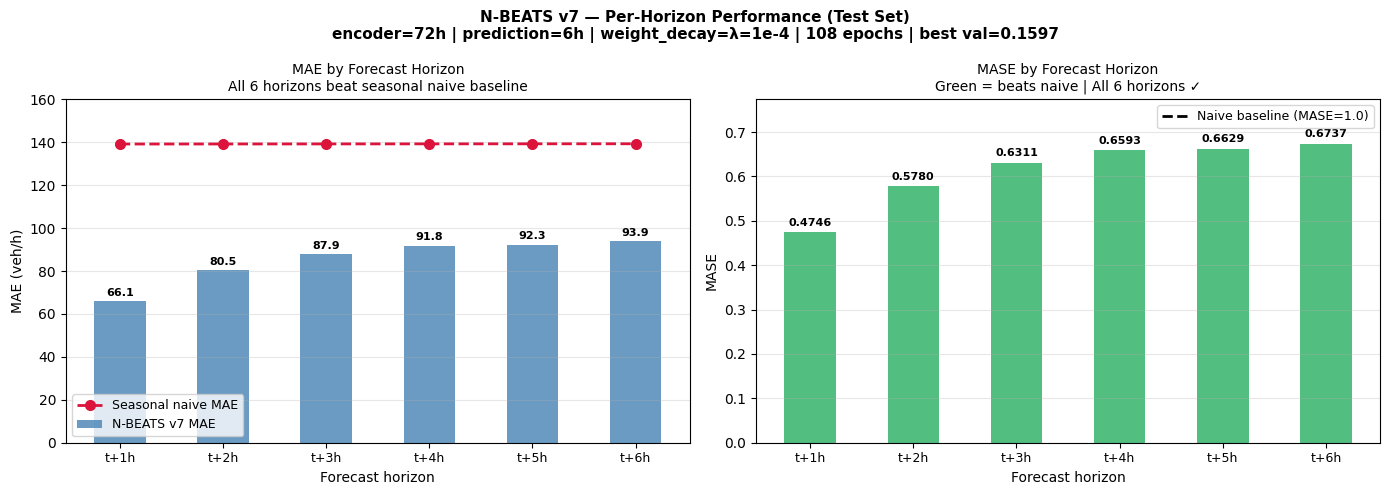

Saved: /home/iai-labor/traffic_project/nbeats_figures_v7/nbeats_v7_horizon_metrics.png

Per-horizon test summary:
  Horizon       MAE     MASE   vs naive
  --------------------------------------
  t+1h        66.07   0.4746     52.5% better
  t+2h        80.47   0.5780     42.2% better
  t+3h        87.89   0.6311     36.9% better
  t+4h        91.84   0.6593     34.1% better
  t+5h        92.35   0.6629     33.7% better
  t+6h        93.87   0.6737     32.6% better
  Overall     85.42   0.6133


In [9]:
# ── Per-horizon MAE and MASE bar charts ───────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    "N-BEATS v7 — Per-Horizon Performance (Test Set)\n"
    "encoder=72h | prediction=6h | weight_decay=λ=1e-4 | "
    "108 epochs | best val=0.1597",
    fontsize=11, fontweight="bold"
)

horizons   = [f"t+{h+1}h" for h in range(FIXED["max_prediction_length"])]
maes       = [horizon_metrics_test[h]["MAE"]  for h in horizons]
mases      = [horizon_metrics_test[h]["MASE"] for h in horizons]
naive_maes = [horizon_naive_test[h]            for h in horizons]
x          = np.arange(len(horizons))

# ── Panel 1: MAE vs Naive MAE ─────────────────────────────────────────────────
ax1 = axes[0]
bars = ax1.bar(x, maes, color="steelblue",
               alpha=0.8, width=0.5, label="N-BEATS v7 MAE")
ax1.plot(x, naive_maes, color="crimson", linewidth=2.0,
         marker="o", markersize=7, linestyle="--",
         label="Seasonal naive MAE")

for bar, mae in zip(bars, maes):
    ax1.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 1.5,
             f"{mae:.1f}", ha="center", va="bottom",
             fontsize=8, fontweight="bold")

ax1.set_xticks(x)
ax1.set_xticklabels(horizons, fontsize=9)
ax1.set_xlabel("Forecast horizon", fontsize=10)
ax1.set_ylabel("MAE (veh/h)", fontsize=10)
ax1.set_title(
    "MAE by Forecast Horizon\n"
    "All 6 horizons beat seasonal naive baseline",
    fontsize=10
)
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3, axis="y")
ax1.set_ylim(0, max(max(maes), max(naive_maes)) * 1.15)

# ── Panel 2: MASE ─────────────────────────────────────────────────────────────
ax2 = axes[1]
bar_colors = ["#27ae60" if m < 1.0 else "#e74c3c" for m in mases]
bars2 = ax2.bar(x, mases, color=bar_colors, alpha=0.8, width=0.5)
ax2.axhline(y=1.0, color="black", linewidth=2.0,
            linestyle="--", label="Naive baseline (MASE=1.0)")

for bar, mase in zip(bars2, mases):
    ax2.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.01,
             f"{mase:.4f}", ha="center", va="bottom",
             fontsize=8, fontweight="bold")

ax2.set_xticks(x)
ax2.set_xticklabels(horizons, fontsize=9)
ax2.set_xlabel("Forecast horizon", fontsize=10)
ax2.set_ylabel("MASE", fontsize=10)
ax2.set_title(
    "MASE by Forecast Horizon\n"
    "Green = beats naive | All 6 horizons ✓",
    fontsize=10
)
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3, axis="y")
ax2.set_ylim(0, max(mases) * 1.15)

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "nbeats_v7_horizon_metrics.png")
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")
print()
print("Per-horizon test summary:")
print(f"  {'Horizon':<8} {'MAE':>8} {'MASE':>8} {'vs naive':>10}")
print(f"  {'-'*38}")
for h in horizons:
    m = horizon_metrics_test[h]
    n = horizon_naive_test[h]
    improvement = (1 - m['MASE']) * 100
    print(f"  {h:<8} {m['MAE']:>8.2f} {m['MASE']:>8.4f} "
          f"  {improvement:>6.1f}% better")
print(f"  {'Overall':<8} {overall_test['MAE']:>8.2f} "
      f"{overall_test['MASE']:>8.4f}")

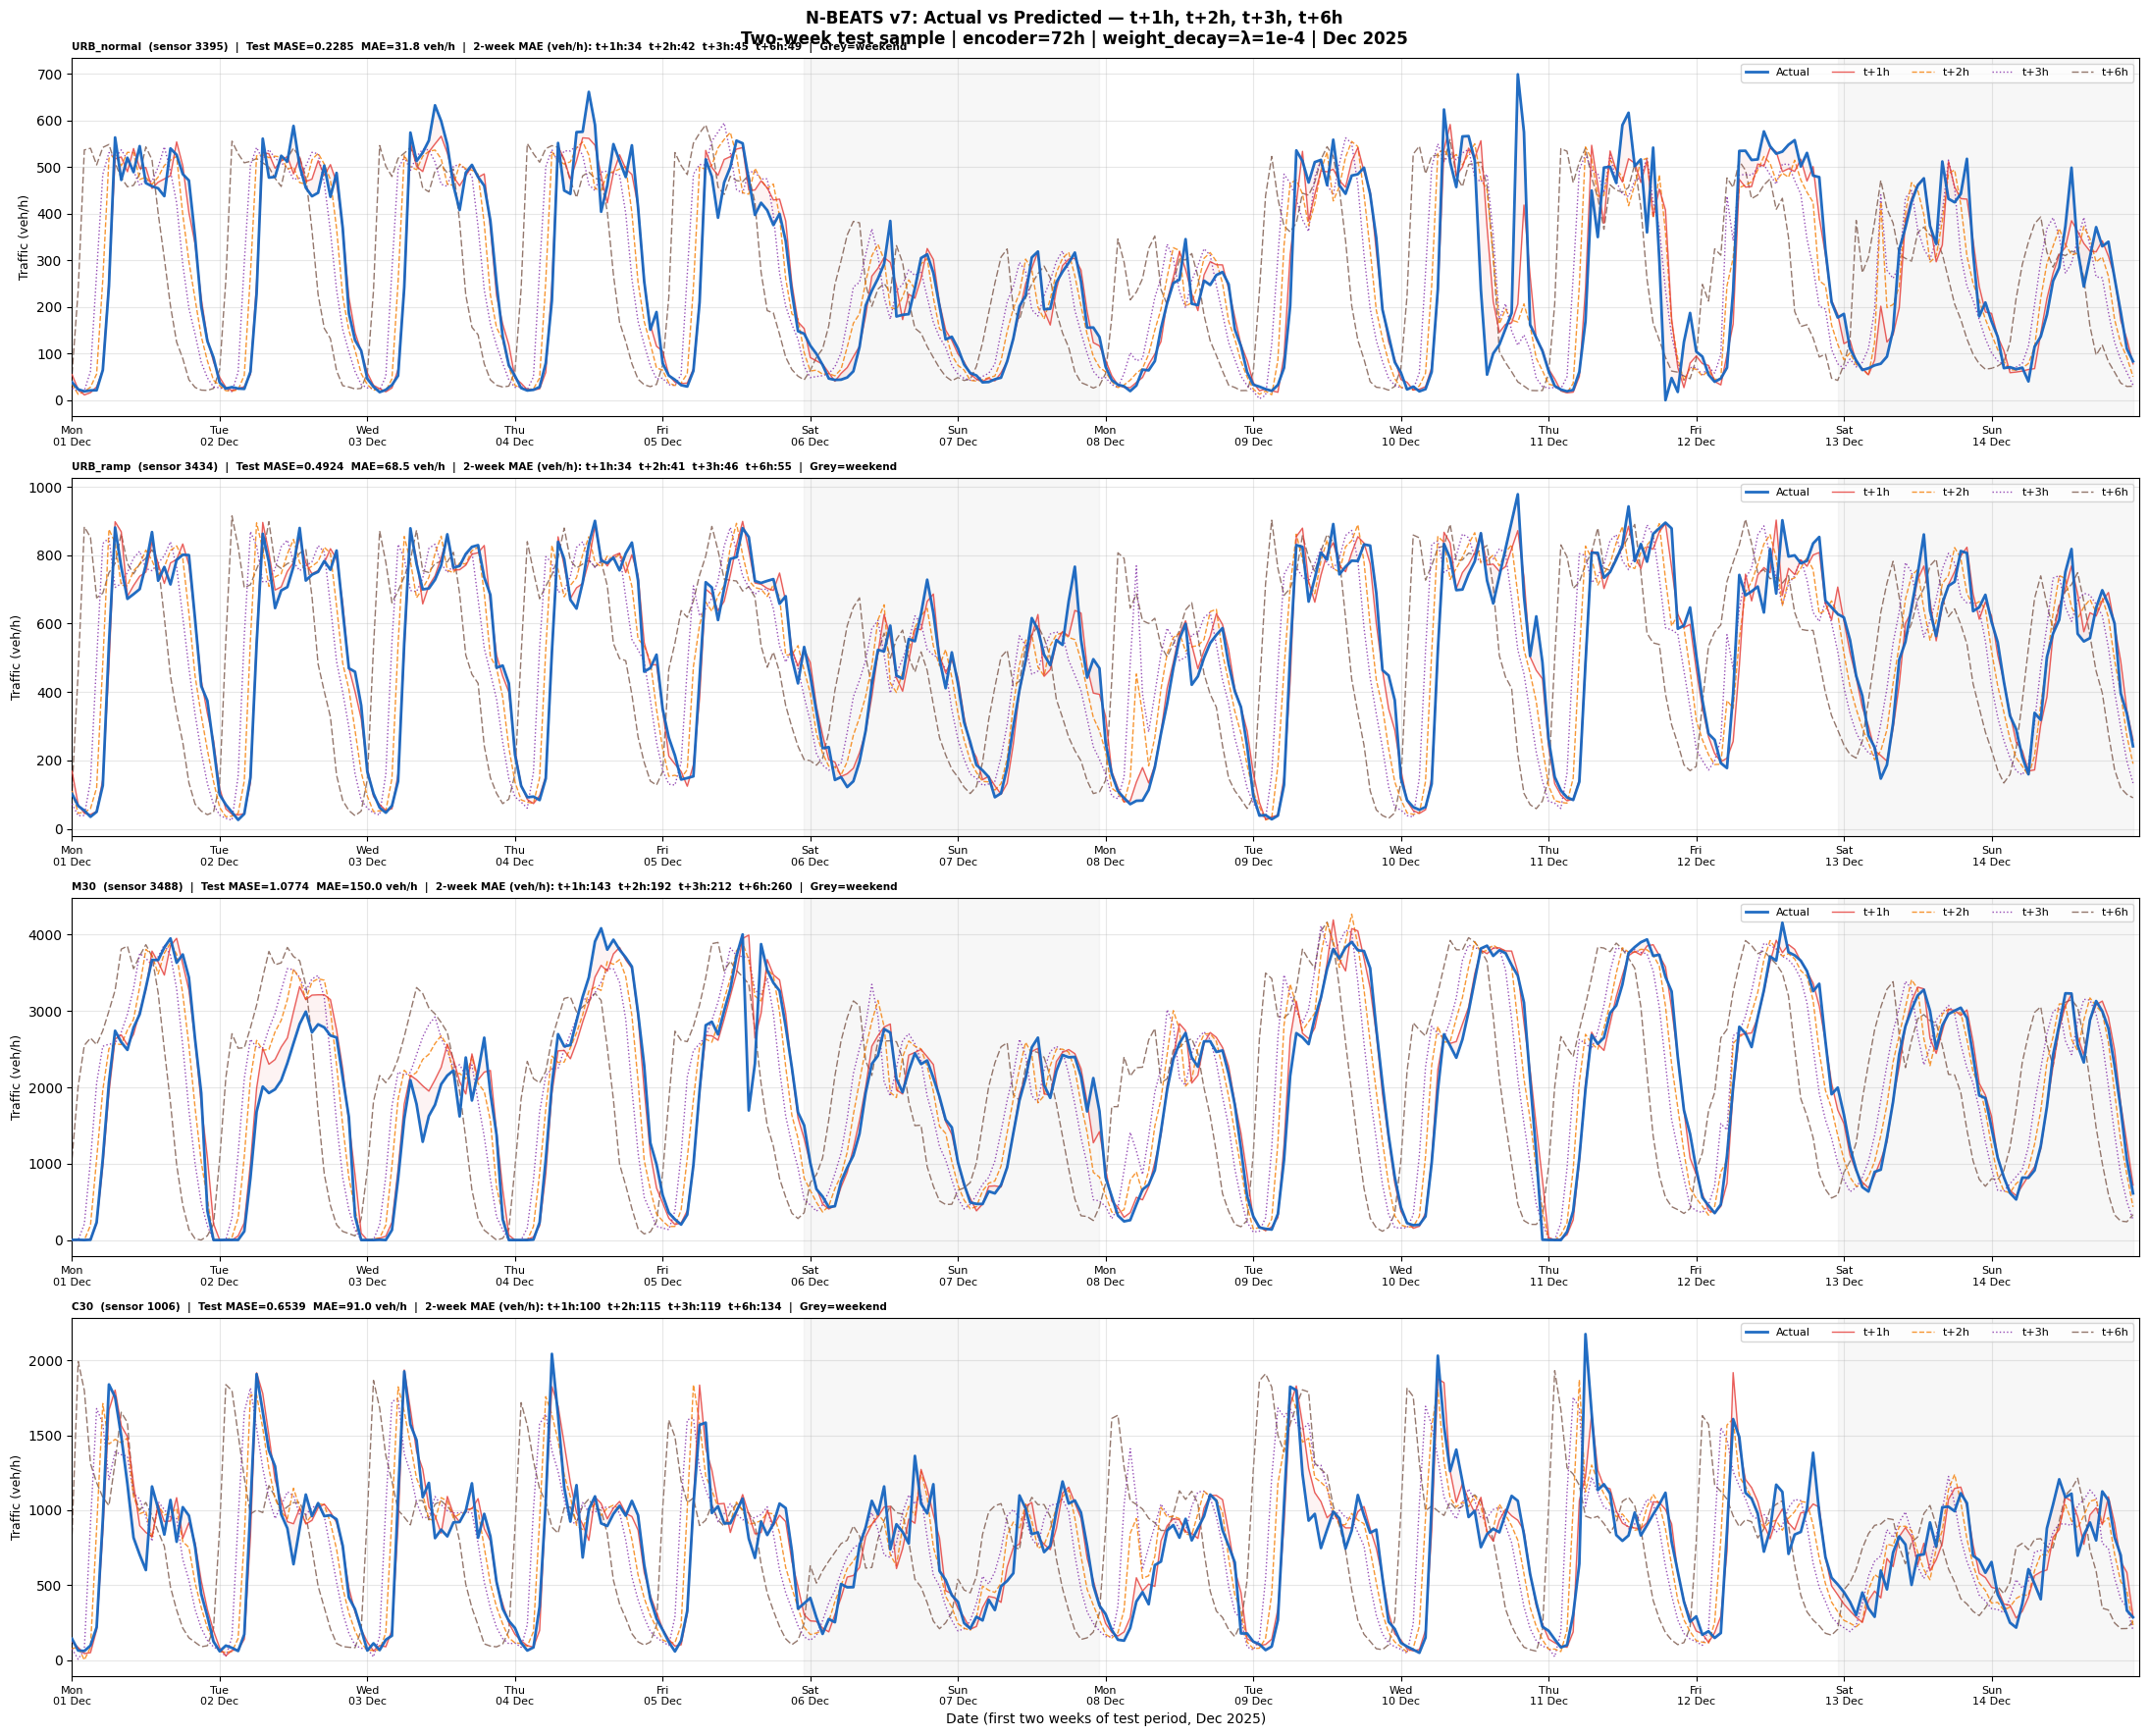

Saved: /home/iai-labor/traffic_project/nbeats_figures_v7/nbeats_v7_twoweek_4horizons.png


In [10]:
# ── Two-week plot: t+1, t+2, t+3, t+6 horizons only ─────────────────────────
PLOT_SENSORS = {
    "URB_normal": 3395,
    "URB_ramp":   3434,
    "M30":        3488,
    "C30":        1006,
}
TWO_WEEKS = 24 * 14

SELECTED_HORIZONS = {
    "t+1h": (0, "#E53935", "-"),
    "t+2h": (1, "#F57C00", "--"),
    "t+3h": (2, "#7B1FA2", ":"),
    "t+6h": (5, "#795548", (0,(5,2))),
}

fig, axes = plt.subplots(4, 1, figsize=(22, 18), sharex=False)
fig.suptitle(
    "N-BEATS v7: Actual vs Predicted — t+1h, t+2h, t+3h, t+6h\n"
    "Two-week test sample | encoder=72h | weight_decay=λ=1e-4 | "
    "Dec 2025",
    fontsize=12, fontweight="bold"
)

for ax, (label, sensor_id) in zip(axes, PLOT_SENSORS.items()):
    sid_str        = str(sensor_id)
    sensor_mask    = sensor_arr == sid_str
    sensor_indices = np.where(sensor_mask)[0]

    if len(sensor_indices) == 0:
        ax.set_title(f"{label} — sensor {sensor_id} not found")
        continue

    n_show   = min(TWO_WEEKS, len(sensor_indices))
    plot_idx = sensor_indices[:n_show]
    actuals_t1 = actual_veh[plot_idx, 0]

    window_dts = pd.to_datetime([
        time_origin + pd.Timedelta(hours=int(ts_arr[i, 0]))
        for i in plot_idx
    ])
    window_dts_list = list(window_dts)
    x = np.arange(n_show)

    # Actual
    ax.plot(x, actuals_t1, color="#1565C0", linewidth=2.0,
            alpha=0.95, label="Actual", zorder=7)

    # 4 selected horizons
    for h_label, (h_idx, color, style) in SELECTED_HORIZONS.items():
        ax.plot(x, pred_veh[plot_idx, h_idx],
                color=color, linewidth=1.0,
                linestyle=style, alpha=0.80,
                label=h_label, zorder=6-h_idx)

    # Error fill t+1h
    ax.fill_between(x, actuals_t1, pred_veh[plot_idx, 0],
                    alpha=0.06, color="#E53935", zorder=2)

    # Weekend shading
    dow_vals = pd.Series(window_dts).dt.dayofweek
    i = 0
    while i < len(window_dts_list):
        if dow_vals.iloc[i] == 5:
            j = i
            while j < len(window_dts_list) and \
                    dow_vals.iloc[j] in [5, 6]:
                j += 1
            ax.axvspan(i, j, alpha=0.06, color="gray", zorder=0)
            i = j
        else:
            i += 1

    # Per-horizon 2-week MAEs
    mae_str = "  ".join([
        f"{h_label}:{np.mean(np.abs(pred_veh[plot_idx,h_idx]-actual_veh[plot_idx,h_idx])):.0f}"
        for h_label, (h_idx, _, _) in SELECTED_HORIZONS.items()
    ])
    mase_sc = subclass_results.get(label, {}).get("MASE", 0)
    mae_sc  = subclass_results.get(label, {}).get("MAE",  0)

    day_ticks  = list(range(0, n_show, 24))
    day_labels = [
        window_dts_list[t].strftime("%a\n%d %b")
        for t in day_ticks if t < n_show
    ]
    ax.set_xticks(day_ticks[:len(day_labels)])
    ax.set_xticklabels(day_labels, fontsize=8)
    ax.set_xlim(0, n_show)

    ax.set_title(
        f"{label}  (sensor {sensor_id})  |  "
        f"Test MASE={mase_sc:.4f}  MAE={mae_sc:.1f} veh/h  |  "
        f"2-week MAE (veh/h): {mae_str}  |  Grey=weekend",
        fontsize=7.5, fontweight="bold", loc="left"
    )
    ax.set_ylabel("Traffic (veh/h)", fontsize=9)
    ax.legend(loc="upper right", fontsize=8, ncol=5)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel(
    "Date (first two weeks of test period, Dec 2025)", fontsize=10
)
plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "nbeats_v7_twoweek_4horizons.png")
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

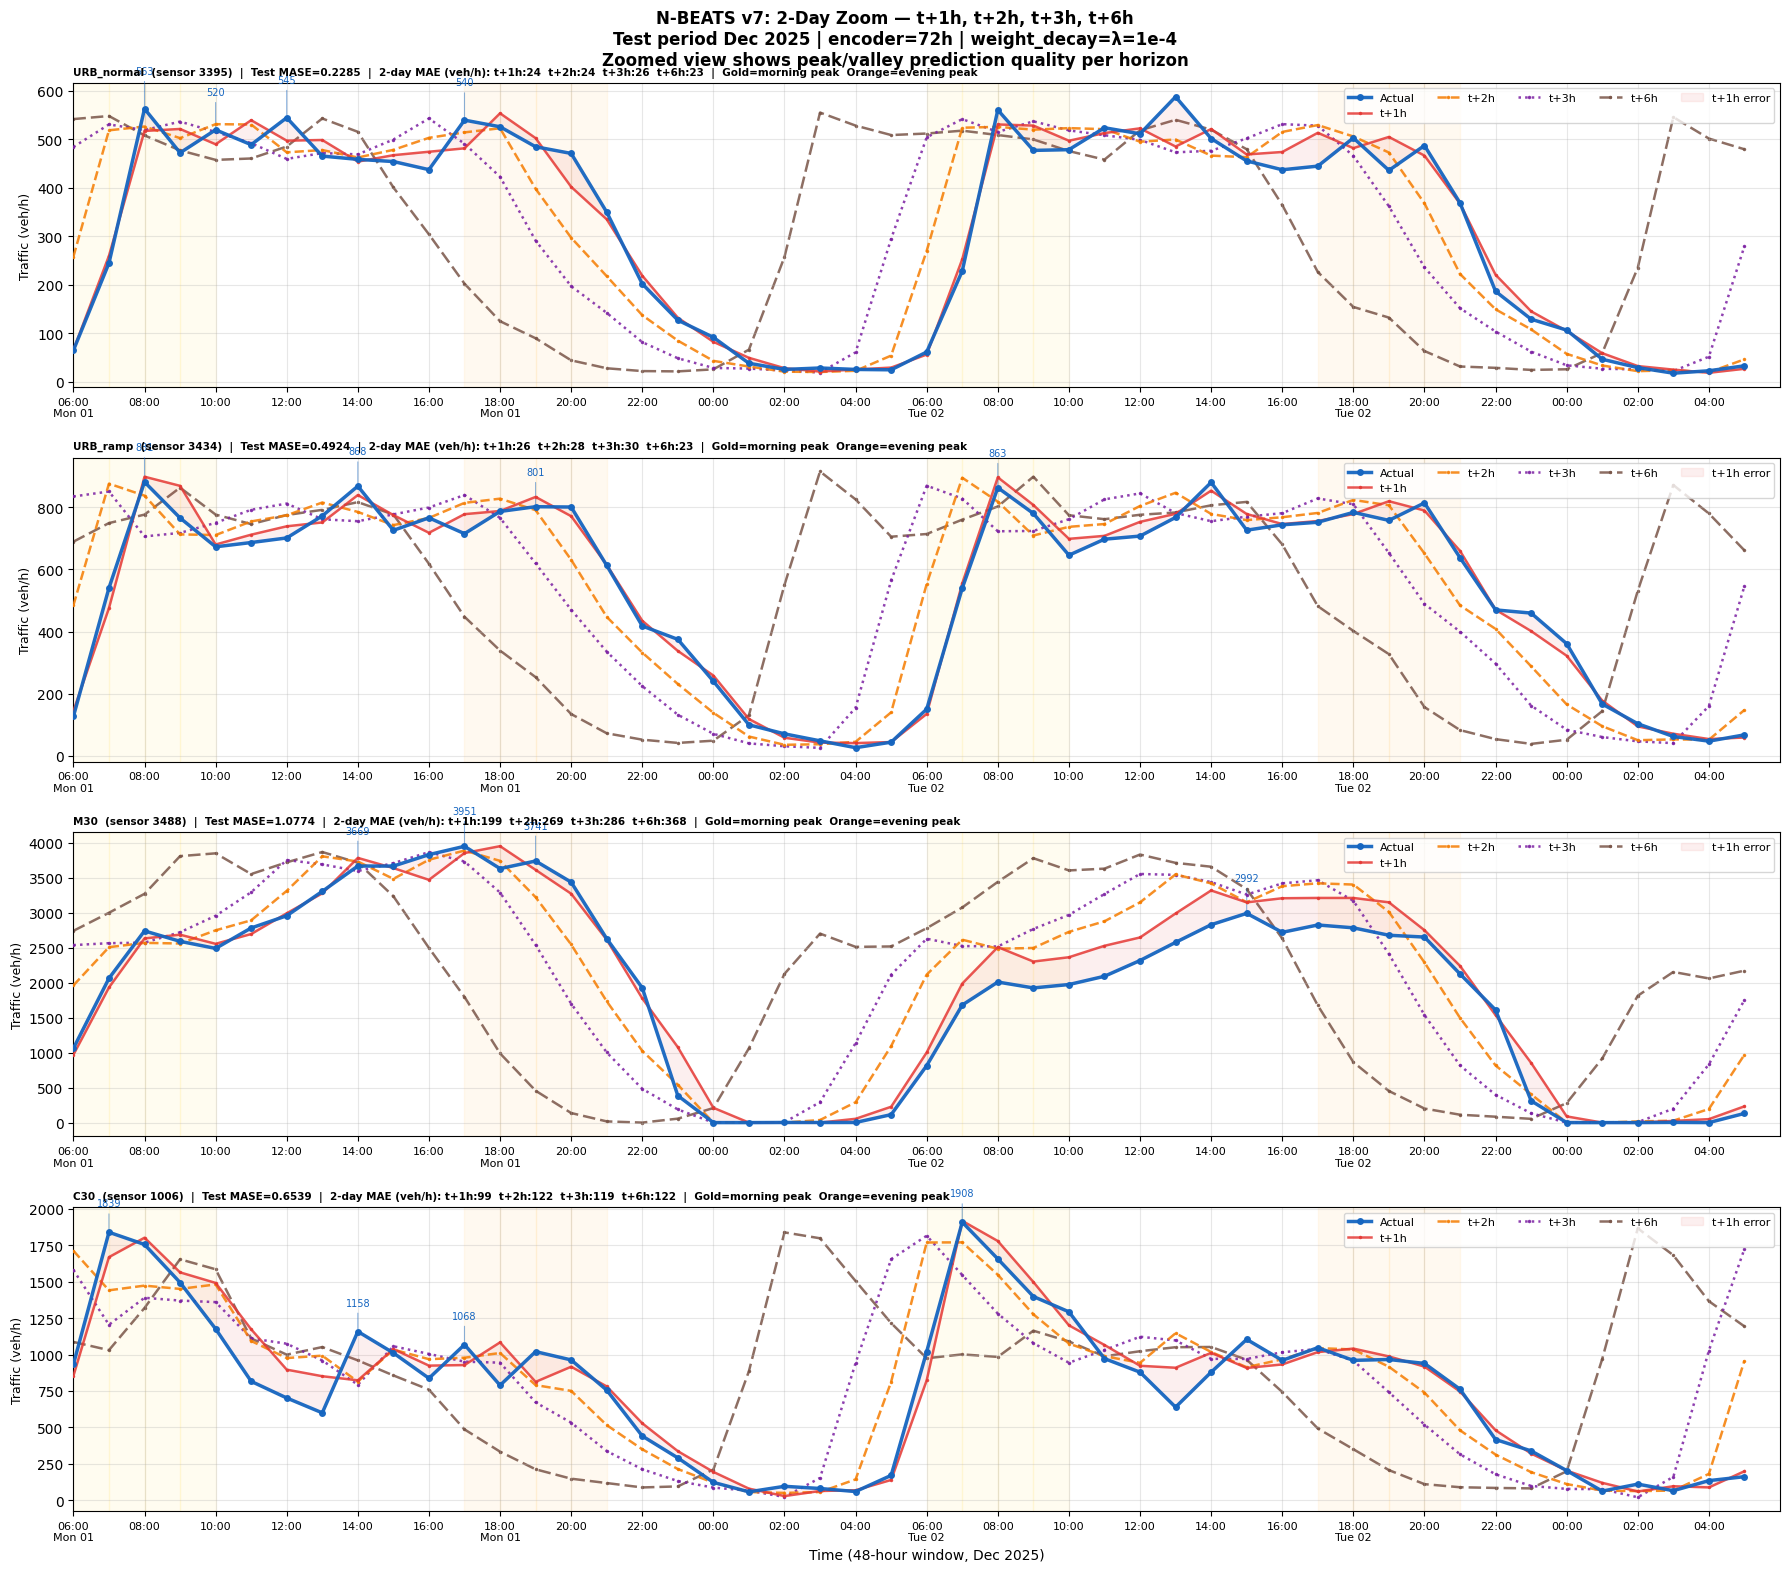

Saved: /home/iai-labor/traffic_project/nbeats_figures_v7/nbeats_v7_twoday_4horizons.png


In [11]:
# ── Two-day zoom: t+1, t+2, t+3, t+6 — clearer peak/valley view ──────────────
TWO_DAYS = 24 * 2

fig, axes = plt.subplots(4, 1, figsize=(18, 16), sharex=False)
fig.suptitle(
    "N-BEATS v7: 2-Day Zoom — t+1h, t+2h, t+3h, t+6h\n"
    "Test period Dec 2025 | encoder=72h | weight_decay=λ=1e-4\n"
    "Zoomed view shows peak/valley prediction quality per horizon",
    fontsize=12, fontweight="bold"
)

for ax, (label, sensor_id) in zip(axes, PLOT_SENSORS.items()):
    sid_str        = str(sensor_id)
    sensor_mask    = sensor_arr == sid_str
    sensor_indices = np.where(sensor_mask)[0]

    if len(sensor_indices) == 0:
        ax.set_title(f"{label} — sensor {sensor_id} not found")
        continue

    # Find Monday 06:00 start for clean 2-day weekday window
    start_idx = None
    for idx in sensor_indices:
        t0_hours = int(ts_arr[idx, 0])
        dt       = time_origin + pd.Timedelta(hours=t0_hours)
        if dt.dayofweek == 0 and dt.hour == 6:
            start_idx = idx
            break
    if start_idx is None:
        start_idx = sensor_indices[0]

    start_pos = np.where(sensor_indices == start_idx)[0][0]
    n_show    = min(TWO_DAYS,
                    len(sensor_indices) - start_pos)
    plot_idx  = sensor_indices[start_pos: start_pos + n_show]

    actuals_t1 = actual_veh[plot_idx, 0]
    window_dts = pd.to_datetime([
        time_origin + pd.Timedelta(hours=int(ts_arr[i, 0]))
        for i in plot_idx
    ])
    window_dts_list = list(window_dts)
    x = np.arange(n_show)

    # Actual
    ax.plot(x, actuals_t1, color="#1565C0", linewidth=2.5,
            alpha=0.95, label="Actual",
            zorder=7, marker="o", markersize=4)

    # 4 selected horizons
    for h_label, (h_idx, color, style) in SELECTED_HORIZONS.items():
        ax.plot(x, pred_veh[plot_idx, h_idx],
                color=color, linewidth=1.8,
                linestyle=style, alpha=0.85,
                label=h_label, zorder=6-h_idx,
                marker=".", markersize=3)

    # Error fill t+1h
    ax.fill_between(x, actuals_t1, pred_veh[plot_idx, 0],
                    alpha=0.08, color="#E53935",
                    zorder=2, label="t+1h error")

    # Morning and evening peak shading
    for i, dt in enumerate(window_dts_list):
        if 6 <= dt.hour <= 9:
            ax.axvspan(i, i+1, alpha=0.06, color="gold",   zorder=0)
        elif 17 <= dt.hour <= 20:
            ax.axvspan(i, i+1, alpha=0.06, color="orange", zorder=0)

    # Hour labels — every 2 hours
    hour_ticks  = list(range(0, n_show, 2))
    hour_labels = [
        window_dts_list[t].strftime("%H:%M\n%a %d")
        if t % 12 == 0
        else window_dts_list[t].strftime("%H:%M")
        for t in hour_ticks if t < n_show
    ]
    ax.set_xticks(hour_ticks[:len(hour_labels)])
    ax.set_xticklabels(hour_labels, fontsize=8)
    ax.set_xlim(0, n_show)

    # Annotate peaks
    peak_threshold = np.percentile(actuals_t1, 75)
    peak_signal    = np.concatenate(
        [[actuals_t1[0]], actuals_t1, [actuals_t1[-1]]]
    )
    peaks = np.where(
        (actuals_t1 > peak_threshold) &
        (np.diff(np.sign(np.diff(peak_signal))) < 0)
    )[0]
    for pk in peaks[:4]:
        ax.annotate(
            f"{actuals_t1[pk]:.0f}",
            xy=(pk, actuals_t1[pk]),
            xytext=(pk, actuals_t1[pk] + actuals_t1.std()*0.35),
            fontsize=7, color="#1565C0", ha="center",
            arrowprops=dict(arrowstyle="-", color="#1565C0",
                            lw=0.8, alpha=0.5)
        )

    # Per-horizon 2-day MAEs
    mae_str = "  ".join([
        f"{h_label}:{np.mean(np.abs(pred_veh[plot_idx,h_idx]-actual_veh[plot_idx,h_idx])):.0f}"
        for h_label, (h_idx, _, _) in SELECTED_HORIZONS.items()
    ])
    mase_sc = subclass_results.get(label, {}).get("MASE", 0)

    ax.set_title(
        f"{label}  (sensor {sensor_id})  |  "
        f"Test MASE={mase_sc:.4f}  |  "
        f"2-day MAE (veh/h): {mae_str}  |  "
        f"Gold=morning peak  Orange=evening peak",
        fontsize=7.5, fontweight="bold", loc="left"
    )
    ax.set_ylabel("Traffic (veh/h)", fontsize=9)
    ax.legend(loc="upper right", fontsize=8, ncol=5)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel(
    "Time (48-hour window, Dec 2025)", fontsize=10
)
plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "nbeats_v7_twoday_4horizons.png")
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

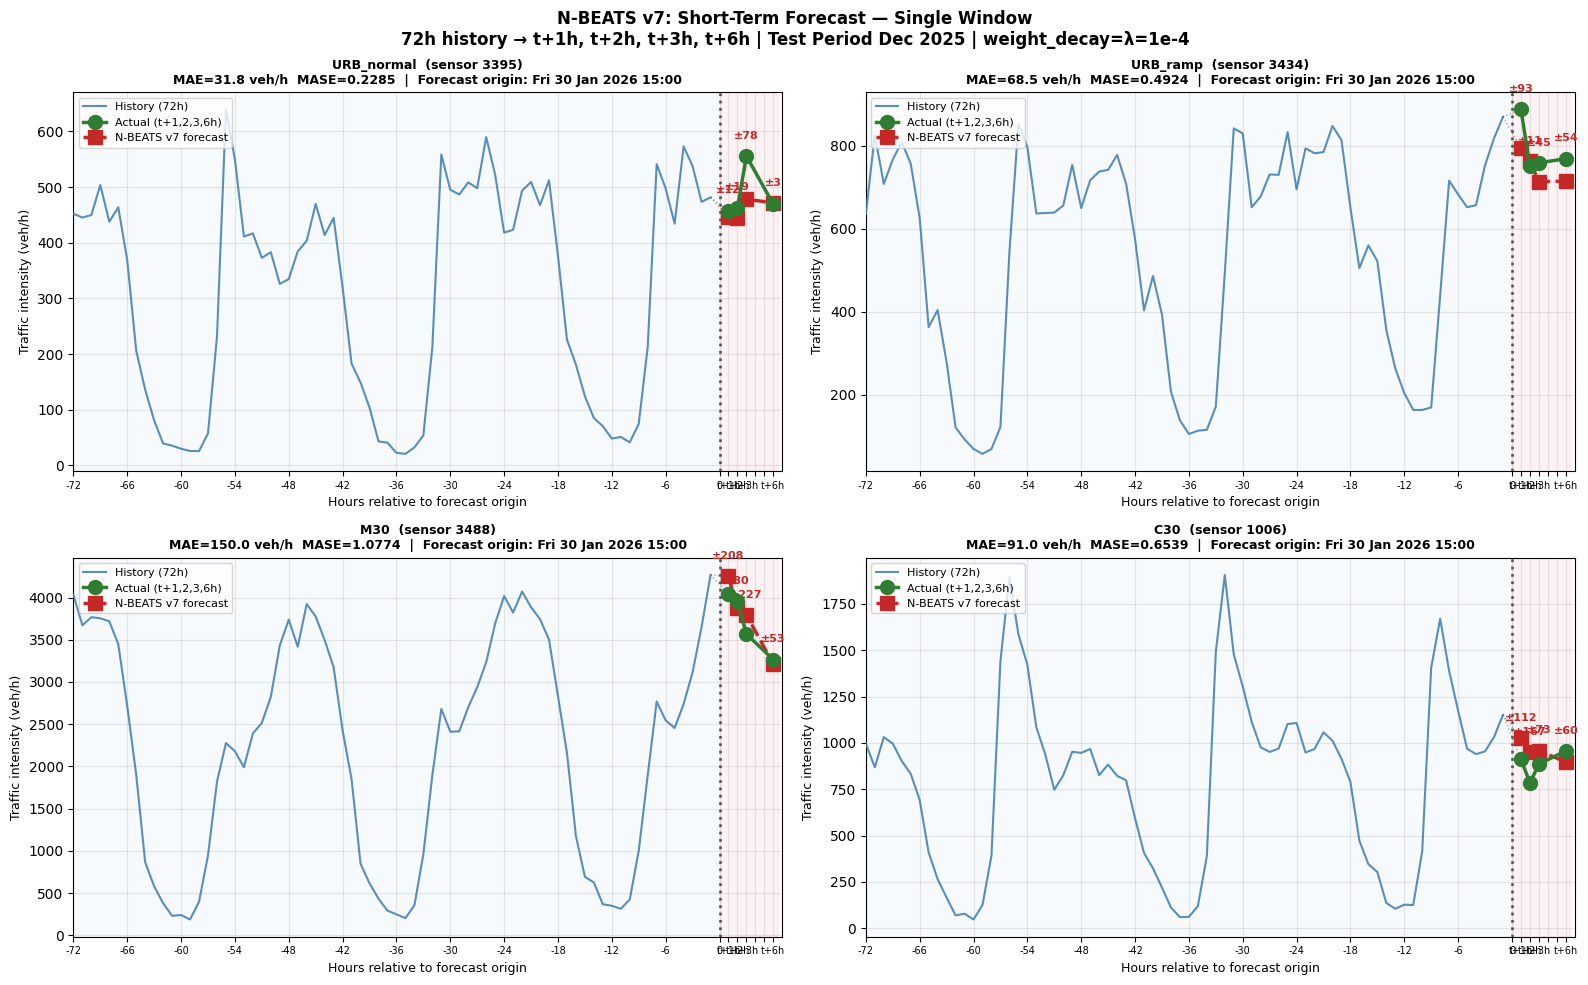

Saved: /home/iai-labor/traffic_project/nbeats_figures_v7/nbeats_v7_snapshot_4horizons.png

All evaluation plots saved:
  nbeats_v7_loss_curves.png
  nbeats_v7_horizon_metrics.png
  nbeats_v7_twoweek_4horizons.png
  nbeats_v7_twoday_4horizons.png
  nbeats_v7_snapshot_4horizons.png


In [12]:
# ── Snapshot: 72h history + t+1, t+2, t+3, t+6 prediction ───────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle(
    "N-BEATS v7: Short-Term Forecast — Single Window\n"
    "72h history → t+1h, t+2h, t+3h, t+6h | "
    "Test Period Dec 2025 | weight_decay=λ=1e-4",
    fontsize=12, fontweight="bold"
)

for ax, (label, sensor_id) in zip(axes.flat, PLOT_SENSORS.items()):
    sid_str        = str(sensor_id)
    sensor_mask    = sensor_arr == sid_str
    sensor_indices = np.where(sensor_mask)[0]

    if len(sensor_indices) == 0:
        ax.set_title(f"{label} — sensor not found")
        continue

    # Find weekday afternoon window with meaningful traffic
    chosen_idx = None
    for idx in sensor_indices[
        len(sensor_indices)//3: len(sensor_indices)//3 + 500
    ]:
        t_pred = int(ts_arr[idx, 0])
        dt     = time_origin + pd.Timedelta(hours=t_pred)
        if (dt.dayofweek < 5 and
                14 <= dt.hour <= 18 and
                actual_veh[idx].mean() > 100):
            chosen_idx = idx
            break
    if chosen_idx is None:
        chosen_idx = sensor_indices[len(sensor_indices)//2]

    pred_vals   = pred_veh[chosen_idx]    # (6,)
    actual_vals = actual_veh[chosen_idx]  # (6,)

    # 72h encoder history from df
    t_start   = int(ts_arr[chosen_idx, 0]) - FIXED["max_encoder_length"]
    t_end     = int(ts_arr[chosen_idx, 0]) - 1
    sensor_df = df[
        (df["SENSOR_ID"] == sensor_id) &
        (df["time_idx"].between(t_start, t_end))
    ].sort_values("time_idx")
    history = sensor_df["target"].values
    if len(history) < FIXED["max_encoder_length"]:
        history = np.pad(
            history,
            (FIXED["max_encoder_length"] - len(history), 0),
            constant_values=0
        )

    history_x = np.arange(-FIXED["max_encoder_length"], 0)  # -72..−1
    future_x  = np.array([1, 2, 3, 6])   # only 4 horizons

    # History line
    ax.plot(history_x, history,
            color="steelblue", linewidth=1.5,
            alpha=0.9, label="History (72h)", zorder=3)

    # Actual and predicted — 4 points only
    h_indices   = [0, 1, 2, 5]   # t+1, t+2, t+3, t+6
    actual_plot = actual_vals[h_indices]
    pred_plot   = pred_vals[h_indices]

    ax.plot(future_x, actual_plot,
            color="#2E7D32", linewidth=2.5,
            marker="o", markersize=10,
            label="Actual (t+1,2,3,6h)", zorder=5)
    ax.plot(future_x, pred_plot,
            color="#C62828", linewidth=2.5,
            marker="s", markersize=10,
            linestyle="--",
            label="N-BEATS v7 forecast", zorder=4)

    # Dotted bridge t+3 → t+6 (skipped t+4, t+5)
    ax.plot([3, 6], [actual_vals[2], actual_vals[5]],
            color="#2E7D32", linewidth=0.8,
            linestyle=":", alpha=0.4, zorder=3)
    ax.plot([3, 6], [pred_vals[2], pred_vals[5]],
            color="#C62828", linewidth=0.8,
            linestyle=":", alpha=0.4, zorder=3)

    # Connect history to first forecast point
    ax.plot([history_x[-1], future_x[0]],
            [history[-1], pred_plot[0]],
            color="#C62828", linewidth=1.0,
            linestyle=":", alpha=0.5, zorder=3)
    ax.plot([history_x[-1], future_x[0]],
            [history[-1], actual_plot[0]],
            color="#2E7D32", linewidth=1.0,
            linestyle=":", alpha=0.5, zorder=3)

    # Forecast origin line
    ax.axvline(x=0, color="black", linestyle=":",
               linewidth=2.0, alpha=0.6)

    # Shading
    ax.axvspan(-FIXED["max_encoder_length"], 0,
               alpha=0.04, color="steelblue")
    ax.axvspan(0, 6.5, alpha=0.06, color="crimson")

    # Error annotations
    y_range = (
        max(history.max(), actual_plot.max(), pred_plot.max()) -
        min(history.min(), actual_plot.min(), pred_plot.min())
    )
    for i, fx in enumerate(future_x):
        err  = abs(pred_plot[i] - actual_plot[i])
        ypos = max(pred_plot[i], actual_plot[i]) + y_range * 0.05
        ax.annotate(f"±{err:.0f}",
                    xy=(fx, ypos),
                    fontsize=8, color="#C62828",
                    ha="center", fontweight="bold")

    # X ticks
    xtick_hist   = list(range(-72, 0, 6))
    xtick_labels = (
        [str(h) for h in xtick_hist] +
        ["0", "t+1h", "t+2h", "t+3h", "", "", "t+6h"]
    )
    ax.set_xticks(xtick_hist + [0, 1, 2, 3, 4, 5, 6])
    ax.set_xticklabels(xtick_labels, fontsize=7)
    ax.set_xlim(-72, 7)

    forecast_dt = (
        time_origin + pd.Timedelta(hours=int(ts_arr[chosen_idx, 0]))
    ).strftime("%a %d %b %Y %H:%M")
    mae_sc  = subclass_results.get(label, {}).get("MAE",  0)
    mase_sc = subclass_results.get(label, {}).get("MASE", 0)

    ax.set_title(
        f"{label}  (sensor {sensor_id})\n"
        f"MAE={mae_sc:.1f} veh/h  MASE={mase_sc:.4f}  |  "
        f"Forecast origin: {forecast_dt}",
        fontsize=9, fontweight="bold"
    )
    ax.set_xlabel("Hours relative to forecast origin", fontsize=9)
    ax.set_ylabel("Traffic intensity (veh/h)", fontsize=9)
    ax.legend(fontsize=8, loc="upper left")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "nbeats_v7_snapshot_4horizons.png")
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")
print()
print("All evaluation plots saved:")
print(f"  nbeats_v7_loss_curves.png")
print(f"  nbeats_v7_horizon_metrics.png")
print(f"  nbeats_v7_twoweek_4horizons.png")
print(f"  nbeats_v7_twoday_4horizons.png")
print(f"  nbeats_v7_snapshot_4horizons.png")